### Evaluation

Notebook to run evaulation on test data

- use daily provided data (evaluation period of competition)

Data: "../data/evaluation/[met_nowcast_daily, met_forecast_daily, wind_power]"


In [1]:
import os
import sys

sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from jax import random
from numpyro.infer import Predictive
import arviz as az

from validate_example import validate_forecast
from data_processing.load import (
    load_evaluation_data,
    load_weather_forecast_parquet,
    load_and_preprocess_forecast_data,
    rename_met_forecast_columns,
    sin_cos_transform,
    load_weather_nowcast,
    load_evaluation_forecast_data,
    load_scaler_params,
)
from training.plot import (
    plot_qr_hdi_prediction_ensemble,
    plot_bnn_gamma_combined,
    plot_qr_hdi_prediction_ensemble_combined,
)
from models.model import model_mw_gamma, model_cf_logitnormal, model_cf_beta
from training.evaluate import test_QR, test_BNN, crps_from_quantiles
import torch
import re

from configs.load_config import load_config
from models.build import build_model
from data_processing.utils import load_checkpoint, extract_test_dates

import properscoring as ps

In [2]:
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import plot_bnn_gamma_combined

### Load evaluation data


In [3]:
representative_test_set = False

In [4]:
# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_01_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-03-28_14-17-43_nowcast_ELSPOT_NO1"

model_cfg = load_config("../configs/model/torch_model_quantile.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "WindPowerQuantile_weighted_2026-04-07_17-04-37_nowcast_gen_ELSPOT_NO1"

In [5]:
from types import SimpleNamespace

data_cfg.dataset = "forecast"
data_cfg.ensemble = SimpleNamespace(members=None, variance=False)

In [6]:
bid_zone = model_cfg.data.bid_zone
bid_zones = ["ELSPOT NO1", "ELSPOT NO2", "ELSPOT NO3", "ELSPOT NO4"]
bid_zones = [bz.replace(" ", "_") for bz in bid_zones]

# Scale nowcast and forecast with same scalers
scaler_data_nowcast = load_scaler_params(
    bid_zone=bid_zone, dataset="nowcast", dir_path="../checkpoints"
)

dataset = "forecast"  # data_cfg.dataset
if dataset == "nowcast":
    evaluation_dates = [
        "2025-09-22",
        "2025-09-23",
        "2025-09-24",
        "2025-09-25",
        "2025-09-26",
        "2025-09-29",
        "2025-09-30",
        # "2025-10-01",
        # "2025-10-02",
        # "2025-10-03",
    ]

    eval_data = load_evaluation_data(
        dates=evaluation_dates,
        scaler_params=scaler_data_nowcast["scaler_params"],
        site_scaler_params=scaler_data_nowcast["site_scaler_params"],
        bid_zone=bid_zone,
    )

elif dataset == "forecast":
    evaluation_dates = (
        [
            "2025-09-22",
            "2025-09-23",
            "2025-09-24",
            "2025-09-25",
            "2025-09-26",
            "2025-09-29",
            "2025-09-30",
            "2025-10-01",
            "2025-10-02",
            "2025-10-03",
        ]
        if not representative_test_set
        else extract_test_dates()
    )

    eval_data = load_evaluation_forecast_data(
        dates=evaluation_dates,
        scaler_params=scaler_data_nowcast["scaler_params"],
        site_scaler_params=scaler_data_nowcast["site_scaler_params"],
        bid_zone=bid_zone,
        ensemble_members=None,
        variance_feature=False,
    )

Loaded scaler parameters for ELSPOT NO1 and nowcast
  Saved at: 2026-04-07 15:22:40
  Split time: 2025-01-01 00:00:00+01:00
Loading evaluation data for 10 dates in zone ELSPOT NO1...
Loading evaluation data for 2025-09-22 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-23 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-24 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-25 i

Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 0
Preprocessing done. X_eval shape: (240, 6, 15, 10)
Dropped timestamps due to maintenance: 0


In [7]:
# assert np.allclose(eval_data["X_eval"], eval_data_eff["X_eval"])

In [8]:
model_name_for_title = "BNN" if model_cfg.backend == "numpyro" else "QRNN"

### Evaluate on test set


In [9]:
forecasts_ext = []
preds_list = []
for member in range(15):

    if model_cfg.backend == "numpyro":

        forecast, forecast_extended, bz_from_checkpoint, preds = test_BNN(
            file_name, eval_data, member=member
        )

    elif model_cfg.backend == "torch":

        forecast, forecast_extended, bz_from_checkpoint, preds = test_QR(
            file_name,
            eval_data,
            ensembles=False,
            from_now_to_forecast=True,
            member=member,
        )
        checkpoint = torch.load(
            os.path.join("../checkpoints", f"{file_name}.pt"),
            map_location="cpu",
            weights_only=False,
        )

    forecasts_ext.append(forecast_extended[int(bz_from_checkpoint[-1]) - 1])
    preds_list.append(preds)

    if dataset == "nowcast":
        print("We use nowcast, so only one iteration")
        break

Choose ensemble member 0
[0.    0.025 0.05  0.075 0.1   0.125 0.15  0.175 0.2   0.225 0.25  0.275
 0.3   0.325 0.35  0.375 0.4   0.425 0.45  0.475 0.5   0.525 0.55  0.575
 0.6   0.625 0.65  0.675 0.7   0.725 0.75  0.775 0.8   0.825 0.85  0.875
 0.9   0.925 0.95  0.975 1.   ]
Loaded model: WindPowerQuantile_weighted_2026-04-07_17-04-37_nowcast_gen_ELSPOT_NO1.pt
  Model class: WindPowerQuantile_weighted
[0.    0.025 0.05  0.075 0.1   0.125 0.15  0.175 0.2   0.225 0.25  0.275
 0.3   0.325 0.35  0.375 0.4   0.425 0.45  0.475 0.5   0.525 0.55  0.575
 0.6   0.625 0.65  0.675 0.7   0.725 0.75  0.775 0.8   0.825 0.85  0.875
 0.9   0.925 0.95  0.975 1.   ]
(240, 41)
Choose ensemble member 1
[0.    0.025 0.05  0.075 0.1   0.125 0.15  0.175 0.2   0.225 0.25  0.275
 0.3   0.325 0.35  0.375 0.4   0.425 0.45  0.475 0.5   0.525 0.55  0.575
 0.6   0.625 0.65  0.675 0.7   0.725 0.75  0.775 0.8   0.825 0.85  0.875
 0.9   0.925 0.95  0.975 1.   ]
Loaded model: WindPowerQuantile_weighted_2026-04-07_17-04-

In [10]:
df_out = pd.concat(forecasts_ext, axis=1, keys=range(len(forecasts_ext)))

df_out.columns = [f"{col}_{i}" for i, col in df_out.columns]

median_cols = df_out.filter(regex=r"^median_").columns
hdi_lower_cols = df_out.filter(regex=r"^hdi_lower_").columns
hdi_upper_cols = df_out.filter(regex=r"^hdi_upper_").columns

df_out["mean_median"] = df_out[median_cols].mean(axis=1)
df_out["std_median"] = df_out[median_cols].std(axis=1)
df_out["mean_hdi_lower"] = df_out[hdi_lower_cols].mean(axis=1)
df_out["std_hdi_lower"] = df_out[hdi_lower_cols].std(axis=1)
df_out["mean_hdi_upper"] = df_out[hdi_upper_cols].mean(axis=1)
df_out["std_hdi_upper"] = df_out[hdi_upper_cols].std(axis=1)

In [11]:
# # Save predictions to CSV
# data_folder = f"../data/evaluation/eval_period"
# file_path = f"{data_folder}/forecast.csv"
# if not os.path.exists(data_folder):
#     os.makedirs(data_folder)
# forecast.to_csv(file_path)

In [12]:
# # Validate format
# df = validate_forecast(file_path)

### Metrics


In [13]:
# Metrics for member 0
bid_zone = model_cfg.data.bid_zone.replace(" ", "_")
i = int(bid_zone.split("NO")[-1]) - 1
print(i, bid_zone)

rmse = np.sqrt(np.mean((forecast[bid_zone] - eval_data["Y_eval_gen"]) ** 2))

print("Test RMSE (gen prediction):", rmse)
inside = (eval_data["Y_eval_gen"] >= forecasts_ext[0]["hdi_lower"]) & (
    eval_data["Y_eval_gen"] <= forecasts_ext[0]["hdi_upper"]
)
coverage_90 = inside.mean()
print(f"\nEmpirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (eval_data["Y_eval_gen"] <= forecasts_ext[0]["median"]).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")

if model_cfg.backend == "numpyro":
    crps = ps.crps_ensemble(eval_data["Y_eval_gen"], preds, axis=0).mean()
else:
    if checkpoint["model_cfg"].params.quantiles is None:
        if model_cfg.params.num_quantiles is not None:
            quantiles = torch.linspace(0, 1, model_cfg.params.num_quantiles)
        else:
            quantiles = torch.linspace(0, 1, 51)
    else:
        quantiles = torch.tensor(checkpoint["model_cfg"].params.quantiles)
    Y_eval_gen = eval_data["Y_eval_gen"]
    if not isinstance(Y_eval_gen, torch.Tensor):
        Y_eval_gen = torch.tensor(Y_eval_gen, dtype=torch.float32)
    crps = crps_from_quantiles(
        Y_eval_gen,
        preds_list[0],
        quantiles,
    )
print("\nTest CRPS (gen prediction)", crps)

0 ELSPOT_NO1
Test RMSE (gen prediction): 83.56349684068937

Empirical coverage (0.025–0.975): 0.838
Below median (should be ~0.5): 0.333

Test CRPS (gen prediction) tensor(39.2727)


In [14]:
# Metrics across ensemble members (not just member 0)
if data_cfg.dataset == "forecast" and model_cfg.backend == "numpyro":
    stacked_preds = np.concatenate(preds_list, axis=0)
    percentiles_all = np.percentile(stacked_preds, [2.5, 97.5], axis=0)
    results = {}
    Y_test = eval_data["Y_eval_gen"]
    results["rmse_median"] = np.sqrt(
        np.mean((np.median(stacked_preds, axis=0) - Y_test) ** 2)
    )
    results["coverage_025_975"] = (
        (Y_test >= percentiles_all[0]) & (Y_test <= percentiles_all[1])
    ).mean()
    results["coverage_0_50"] = (Y_test <= np.median(stacked_preds)).mean()
    results["crps"] = ps.crps_ensemble(Y_test, stacked_preds, axis=0).mean()

    print(results)

In [15]:
# Metrics across ensemble members (not just member 0)

if data_cfg.dataset == "forecast" and model_cfg.backend == "torch":
    print(quantiles)

    import numpy as np

    ensemble = torch.stack(preds_list, dim=0)  # [15, N, Q]
    ensemble_mean = torch.mean(ensemble, dim=0)  # [N, Q]

    median_idx = torch.argmin(torch.abs(quantiles - 0.5)).item()
    lower_idx = torch.argmin(torch.abs(quantiles - 0.025)).item()
    upper_idx = torch.argmin(torch.abs(quantiles - 0.975)).item()

    y_pred_median = ensemble_mean[:, median_idx]
    y_pred_lower = ensemble_mean[:, lower_idx]
    y_pred_upper = ensemble_mean[:, upper_idx]

    Y_test = eval_data["Y_eval_gen"]
    if not isinstance(Y_test, torch.Tensor):
        Y_test = torch.tensor(Y_test, dtype=ensemble_mean.dtype)

    results = {}
    results["rmse_median"] = torch.sqrt(torch.mean((y_pred_median - Y_test) ** 2))
    results["coverage_025_975"] = (
        ((Y_test >= y_pred_lower) & (Y_test <= y_pred_upper)).float().mean()
    )
    results["coverage_0_50"] = (Y_test <= y_pred_median).float().mean()

    results["crps"] = crps_from_quantiles(
        Y_test,
        ensemble_mean,
        quantiles,
    )

    print(results)

tensor([0.0000, 0.0250, 0.0500, 0.0750, 0.1000, 0.1250, 0.1500, 0.1750, 0.2000,
        0.2250, 0.2500, 0.2750, 0.3000, 0.3250, 0.3500, 0.3750, 0.4000, 0.4250,
        0.4500, 0.4750, 0.5000, 0.5250, 0.5500, 0.5750, 0.6000, 0.6250, 0.6500,
        0.6750, 0.7000, 0.7250, 0.7500, 0.7750, 0.8000, 0.8250, 0.8500, 0.8750,
        0.9000, 0.9250, 0.9500, 0.9750, 1.0000])
{'rmse_median': tensor(77.5815), 'coverage_025_975': tensor(0.8417), 'coverage_0_50': tensor(0.3625), 'crps': tensor(38.2717)}


### Plot prediction


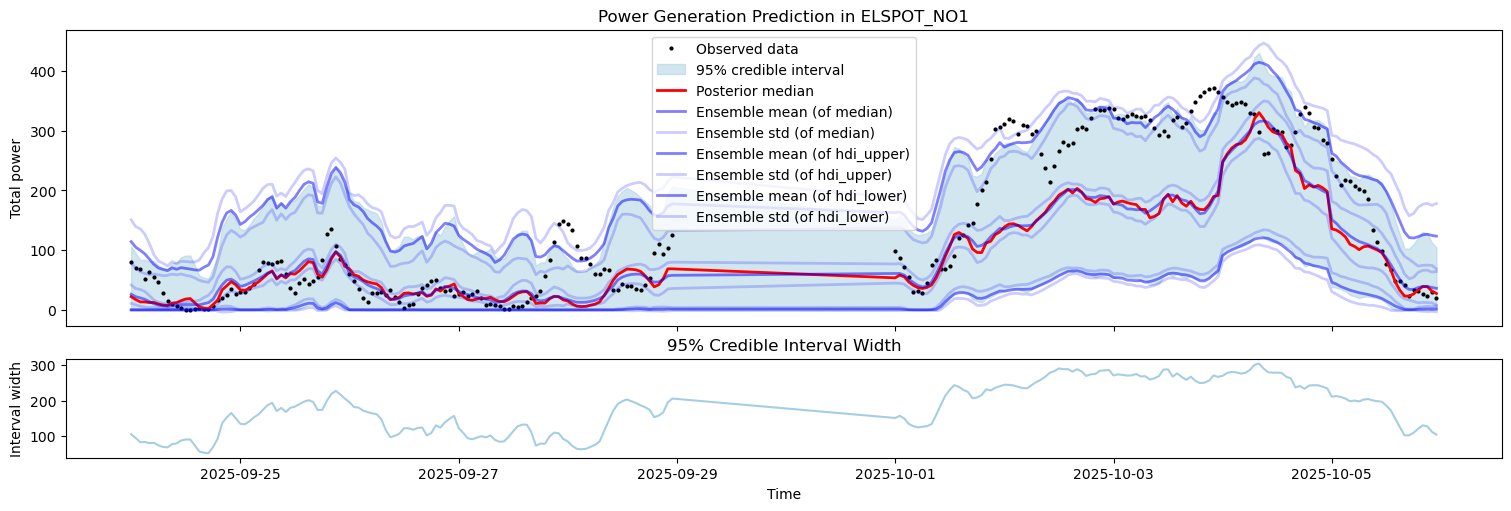

In [16]:
fig, axes = plt.subplots(
    nrows=2,
    figsize=(15, 5),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

ax = axes[0]
ax.plot(
    eval_data["index"],
    eval_data["Y_eval_gen"],
    ".",
    color="black",
    label="Observed data",
    markersize=4,
)

ax.fill_between(
    # np.arange(len(df_out.index)),
    eval_data["index"],
    df_out["hdi_lower_0"].values,
    df_out["hdi_upper_0"].values,
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(
    eval_data["index"],
    df_out["median_0"].values,
    color="red",
    label="Posterior median",
    lw=2,
)

ax.set(
    ylabel="Total power",
    title=f"Power Generation Prediction in {bid_zone}",
)


# Compute interval width
width = df_out["hdi_upper_0"].values - df_out["hdi_lower_0"].values
ax2 = axes[1]
ax2.plot(eval_data["index"], width, color="#A6CEE3")
ax2.set(
    xlabel="Time",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)

keys = ["median", "hdi_upper", "hdi_lower"]
colors = ["blue", "blue", "blue"]

for c, k in zip(colors, keys):
    # Ensemble mean of median
    ax.plot(
        eval_data["index"],
        df_out["mean_" + k].values,
        color=c,
        lw=2,
        alpha=0.5,
        linestyle="-",
        label=f"Ensemble mean (of {k})",
    )
    # Ensemble mean of median
    ax.plot(
        eval_data["index"],
        df_out["mean_" + k].values + df_out["std_" + k].values,
        color=c,
        lw=2,
        alpha=0.2,
        linestyle="-",
        # label=f"Ensemble std (of {k})",
    )
    # Ensemble mean of median
    ax.plot(
        eval_data["index"],
        df_out["mean_" + k].values - df_out["std_" + k].values,
        color=c,
        lw=2,
        alpha=0.2,
        linestyle="-",
        label=f"Ensemble std (of {k})",
    )
ax.legend()

plt.show()

In [17]:
if model_cfg.backend == "numpyro":
    checkpoint = load_checkpoint(file_name=file_name)
    model = build_model(checkpoint["model_cfg"], eval_data)

    plot_bnn_gamma_combined(
        checkpoint, model, eval_data, data_cfg, [0, 5000], split="eval"
    )
    # plt.show()
    title = f"../plots/ensemble_{data_cfg.dataset}_{model_cfg.data.bid_zone}_test"
    if representative_test_set:
        title + "_rep"
    plt.savefig(f"../plots/{title}.pdf")

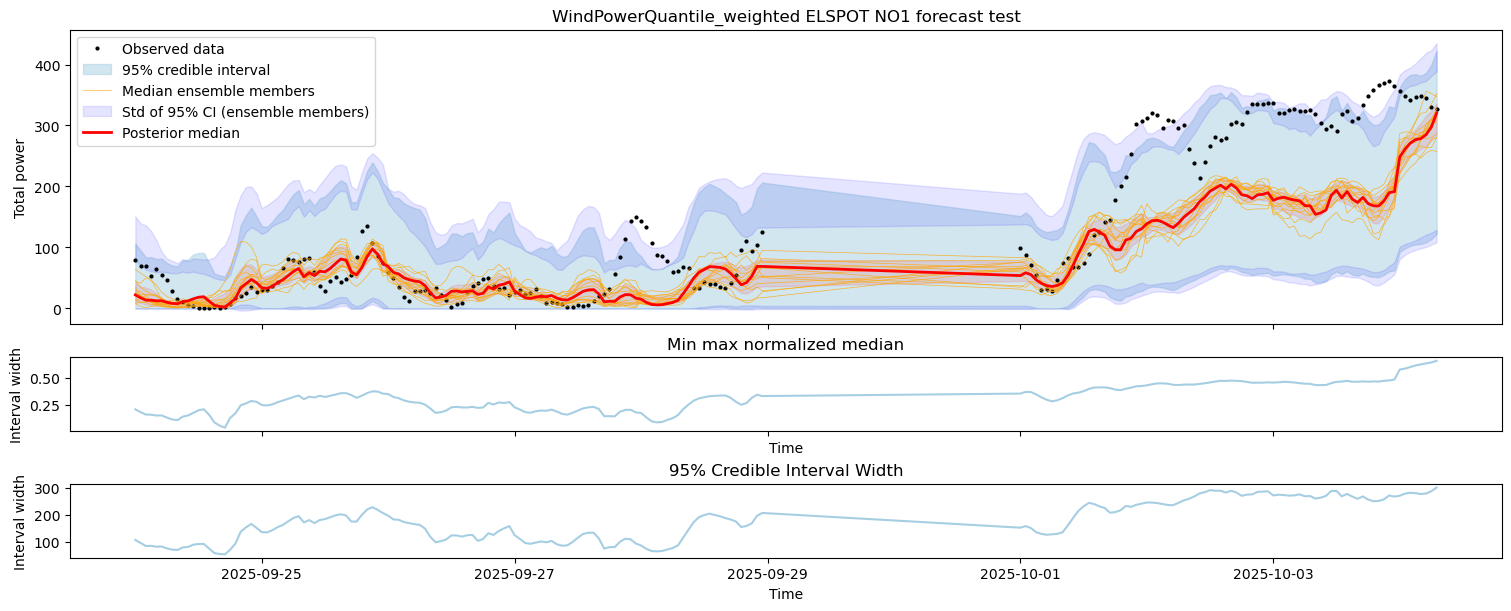

In [18]:
fix, axes = plot_qr_hdi_prediction_ensemble(
    Y_true=eval_data["Y_eval_gen"],
    ensemble_results=df_out,
    plot_interval=[0, 200],
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} test",
    timestamps=eval_data["index"],
)

In [19]:
import importlib
import training.plot as load_plot

importlib.reload(load_plot)

from training.plot import (
    plot_qr_hdi_prediction,
    plot_qr_hdi_prediction_ensemble,
    plot_qr_hdi_prediction_ensemble_outline,
    plot_qr_hdi_prediction_ensemble_std,
    plot_bnn_gamma_combined,
    plot_qr_hdi_prediction_ensemble_combined,
)

In [20]:
if model_cfg.backend == "numpyro":
    checkpoint = load_checkpoint(file_name=file_name)
    model = build_model(checkpoint["model_cfg"], eval_data)

    plot_bnn_gamma_combined(checkpoint, model, eval_data, data_cfg, [0, 663], "eval")
    plt.show()

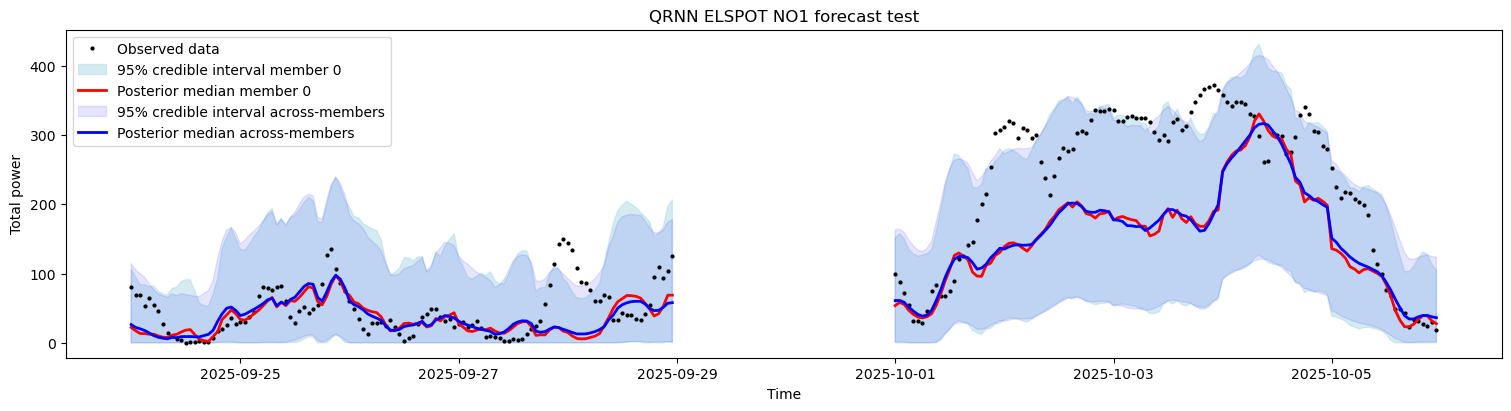

In [21]:
_, _ = plot_qr_hdi_prediction_ensemble_combined(
    Y_true=eval_data["Y_eval_gen"],
    conf_interval=[
        np.stack(
            [df_out["mean_hdi_lower"].values, df_out["mean_hdi_upper"].values], axis=-1
        ),
        np.stack([df_out["hdi_lower_0"].values, df_out["hdi_upper_0"].values], axis=-1),
    ],
    medians=[df_out["mean_median"].values, df_out["median_0"].values],
    plot_interval=[0, 663],
    title=f"{model_name_for_title} {model_cfg.data.bid_zone} {data_cfg.dataset} test",
    timestamps=df_out.index,
)

In [22]:
# # First, load nowcast data (or load existing scaler params)
# nowcast_data = load_and_preprocess_data(bid_zone="ELSPOT NO1")

In [23]:
# # Now load forecast data using the SAME scaler parameters

# forecast_data = load_and_preprocess_forecast_data(
#     scaler_params=None,
#     site_scaler_params=None,
#     bid_zone="ELSPOT NO1",
#     ensemble_member=0,  # Use member 0
#     data_path="../data",
# )

In [24]:
# # Plot cf vs gen model for QR
# fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, constrained_layout=True)

# ax = axes[0]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )

# # file_name = "WindPowerQuantile_2025-12-02_11-34-46_fore_ELSPOT_NO1"
# # file_name="WindPowerModel_simple_2025-12-02_11-11-30_fore_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-04_12-21-40_now_gen_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
# # file_name = "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_QR(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     ylabel="Total power",
#     title=f"QR Power Generation Prediction in {bid_zone}",
# )
# ax.legend(fontsize=14)
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)


# ax = axes[1]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )
# # file_name = "WindPowerQuantile_2025-12-02_11-34-46_fore_ELSPOT_NO1"
# # file_name="WindPowerModel_simple_2025-12-02_11-11-30_fore_ELSPOT_NO1"
# # file_name = "WindPowerQuantile_2025-12-03_14-57-43_now_gen_ELSPOT_NO1"
# file_name = "WindPowerQuantile_2025-12-03_14-54-34_now_cf_ELSPOT_NO1"
# # file_name = "WindPowerModel_simple_2025-12-01_10-31-55_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_QR(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     xlabel="Time Index (Forecast test period)",
#     ylabel="Total power",
#     title=f"QR Capacity Factor Prediction in {bid_zone}",
# )
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)

# plt.show()

In [25]:
# # Plot cf vs gen model for BNN
# fig, axes = plt.subplots(nrows=2, figsize=(10, 7), sharex=True, constrained_layout=True)

# ax = axes[0]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )

# file_name = "model_mw_gamma_2025-11-21_10-30-46_gen_ELSPOT_NO1"
# forecast, forecast_extended = evaluate_BNN(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     ylabel="Total power",
#     title=f"BNN Power Generation Prediction (Gamma) in {bid_zone}",
# )
# ax.legend(fontsize=14)
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)


# ax = axes[1]
# ax.plot(
#     eval_data["Y_eval_gen"],
#     ".",
#     color="black",
#     label="Observed data",
#     markersize=4,
# )
# file_name = "model_cf_beta_2025-12-01_10-03-45_cf_ELSPOT_NO1"

# forecast, forecast_extended = evaluate_BNN(file_name)

# ax.fill_between(
#     np.arange(24 * len(evaluation_dates)),
#     forecast_extended[i]["hdi_lower"].values,
#     forecast_extended[i]["hdi_upper"].values,
#     color="#A6CEE3",
#     alpha=0.5,
#     label="95% credible interval",
# )

# ax.plot(
#     forecast_extended[i]["median"].values, color="red", label="Posterior median", lw=2
# )

# ax.set(
#     xlabel="Time Index (Forecast test period)",
#     ylabel="Total power",
#     title=f"BNN Capacity Factor Prediction (Beta) in {bid_zone}",
# )
# ax.title.set_fontsize(18)
# ax.xaxis.label.set_size(16)
# ax.yaxis.label.set_size(16)

# plt.show()